# TabM: a contemporary neural baseline

This extension evaluates **TabM (ICLR 2025)** on the frozen Dome opportunity-prediction task. It uses the authors' implementation with 32 shared-weight ensemble members. Occurrence, direct quoted-value and two-stage models are compared with the saved classical baselines. The final test from 8 January 2026 remains unopened.

See [the research report](../docs/reports/tabm.md), [the supplied paper](../papers/ICLR-2025-tabm-advancing-tabular-deep-learning-with-parameter-efficient-ensembling-Paper-Conference.pdf), and [the implementation](https://github.com/yandex-research/tabm). This is an application with bounded tuning, not a replication of the paper's multi-dataset benchmark.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import torch
from threadpoolctl import threadpool_limits
from IPython.display import display, Image
from src.models.tabm_study import train_study, verify
from src.simulator.tabm import replay
from src.reporting.tabm import build_report, verify_replay, verify_analysis, LABELS

torch.set_num_threads(4)
MODELS = ROOT / 'results/tabm'
REPLAY = ROOT / 'results/tabm_replay'
BASELINE = ROOT / 'results/opportunity_replay'
RUN_TRAINING = False
RUN_REPLAY = False
REBUILD_REPORT = False
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
# Change MODELS and REPLAY to fresh directories before rebuilding.
with threadpool_limits(limits=4):
    if RUN_TRAINING:
        train_study(MODELS, DEVICE)
    if RUN_REPLAY:
        replay(REPLAY, MODELS, BASELINE)
    if REBUILD_REPORT:
        build_report(MODELS, REPLAY, BASELINE)
    design = verify(MODELS)
    verify_replay(REPLAY, MODELS, BASELINE)
    verify_analysis(MODELS, REPLAY, BASELINE)
print('Verified TabM artifacts, earlier-only fits, frozen comparators and closed final test.')

Verified TabM artifacts, earlier-only fits, frozen comparators and closed final test.


## Training protocol

The input is one event per scheduled scan: 33 order-book/history features, optionally adding event type, topic and age. Unknown future labels remain missing and still consume ranking slots. Training labels are opportunity occurrence and the largest qualifying displayed basket margin within the next window. Neither target uses execution returns.

Each of three expanding outer folds contains two earlier inner validation blocks. Eight declared configurations vary width, depth, dropout, learning rate and weight decay. All use k=32. Classifiers select by recall@5 and value methods by captured peak value@5. Early stopping uses inner ensemble log loss or MSE (patience 16, maximum 100 epochs). Each outer model refits on its full earlier training history for the rounded-up median of the two best inner epochs.

Fixed models use candidate zero and one seed, with inner-selected epoch counts. Tuned models average three separately fitted seeds. The hybrid gives equal weight to the within-scan percentile ranks of tuned TabM occurrence and the frozen combined-feature random forest. No weights are selected using outer results.

In [2]:
display(pd.DataFrame(design['candidates']).rename_axis('candidate'))
display(pd.read_csv(MODELS / 'selected_parameters.csv'))
audit = pd.read_csv(MODELS / 'fit_audit.csv')
fits = audit.dropna(subset=['artifact'])
display(fits.groupby(['fold','task']).agg(fits=('artifact','size'), training_seconds=('fit_seconds','sum'), min_epochs=('epochs','min'), max_epochs=('epochs','max')))
display(audit.dropna(subset=['policy'])[['fold','policy','seed','scan_rows','scan_median_ms']])
print('CPU screening includes preprocessing. Three-seed policy cost includes all three models; the hybrid also needs the forest.')

,n_blocks,d_block,dropout,lr,weight_decay
candidate,,,,,
0,2,128,0.1,0.0020,0.0003
1,1,64,0.0,0.0020,0.0003
2,2,64,0.1,0.0010,0.0010
3,2,128,0.2,0.0010,0.0100
4,3,128,0.1,0.0010,0.0003
5,2,256,0.2,0.0020,0.0010
6,1,128,0.1,0.0005,0.0100
7,3,64,0.2,0.0020,0.0100


,fold,method,candidate,params
0,nov_early,classifier,6,"{""d_block"": 128, ""dropout"": 0.1, ""lr"": 0.0005,..."
1,nov_early,regression,0,"{""d_block"": 128, ""dropout"": 0.1, ""lr"": 0.002, ..."
2,nov_early,two_stage,7,"{""d_block"": 64, ""dropout"": 0.2, ""lr"": 0.002, ""..."
3,nov_late,classifier,2,"{""d_block"": 64, ""dropout"": 0.1, ""lr"": 0.001, ""..."
4,nov_late,regression,5,"{""d_block"": 256, ""dropout"": 0.2, ""lr"": 0.002, ..."
5,nov_late,two_stage,7,"{""d_block"": 64, ""dropout"": 0.2, ""lr"": 0.002, ""..."
6,dec_late,classifier,7,"{""d_block"": 64, ""dropout"": 0.2, ""lr"": 0.002, ""..."
7,dec_late,regression,2,"{""d_block"": 64, ""dropout"": 0.1, ""lr"": 0.001, ""..."
8,dec_late,two_stage,7,"{""d_block"": 64, ""dropout"": 0.2, ""lr"": 0.002, ""..."


fits  training_seconds  min_epochs  max_epochs
fold      task                                                      
dec_late  amount         4          1.562016        38.0        61.0
          classifier     5         36.914215        19.0        26.0
          regression     4         39.371217        30.0        44.0
nov_early amount         4          0.299209         3.0        16.0
          classifier     8         30.897927        30.0        95.0
          regression     3          0.773412         3.0         3.0
nov_late  amount         4          0.440216        19.0        23.0
          classifier     8         26.593173         5.0        28.0
          regression     4         32.369115        40.0        49.0

,fold,policy,seed,scan_rows,scan_median_ms
2,nov_early,tabm_fixed_classifier,20261001,14.0,17.5434
4,nov_early,tabm_tuned_classifier,20261001,14.0,15.6321
6,nov_early,tabm_tuned_classifier,20261002,14.0,14.6511
8,nov_early,tabm_tuned_classifier,20261003,14.0,14.6223
10,nov_early,tabm_fixed_regression,20261001,14.0,15.0349
11,nov_early,tabm_tuned_regression,20261001,14.0,14.4838
13,nov_early,tabm_tuned_regression,20261002,14.0,14.9374
15,nov_early,tabm_tuned_regression,20261003,14.0,15.2965
17,nov_early,tabm_fixed_two_stage,20261001,14.0,30.0030
20,nov_early,tabm_tuned_two_stage,20261001,14.0,26.8333


CPU screening includes preprocessing. Three-seed policy cost includes all three models; the hybrid also needs the forest.


## Opportunity capture

Recall counts known positive event-hours selected. Peak-value capture weights known hours by their maximum displayed basket margin; its denominator is not tradable P&L. N=5 is the tuning budget; N=3 is a sensitivity check using the same fits. The December Fed exclusion reranks the remaining events without retraining.

,model,top_n,captured_positive_windows,positive_windows,recall,peak_value_recall,new_without_scan_recall,selected_unknown
0,fixed_book_logistic,5,376,385,0.9766,0.9943,0.9614,461
1,fixed_book_logistic,3,342,385,0.8883,0.9807,0.8283,117
2,fixed_book_random_forest,5,367,385,0.9532,0.9986,0.9227,1272
3,fixed_book_random_forest,3,339,385,0.8805,0.9845,0.8069,496
4,fixed_combined_random_forest,5,367,385,0.9532,0.9987,0.9227,1439
5,fixed_combined_random_forest,3,334,385,0.8675,0.9776,0.7854,644
6,quoted_gap_rule,5,353,385,0.9169,0.9789,0.8627,1518
7,quoted_gap_rule,3,273,385,0.7091,0.6008,0.5193,1316
8,tabm_fixed_book_classifier,5,369,385,0.9584,0.9967,0.9313,1032
9,tabm_fixed_book_classifier,3,319,385,0.8286,0.9255,0.7167,660


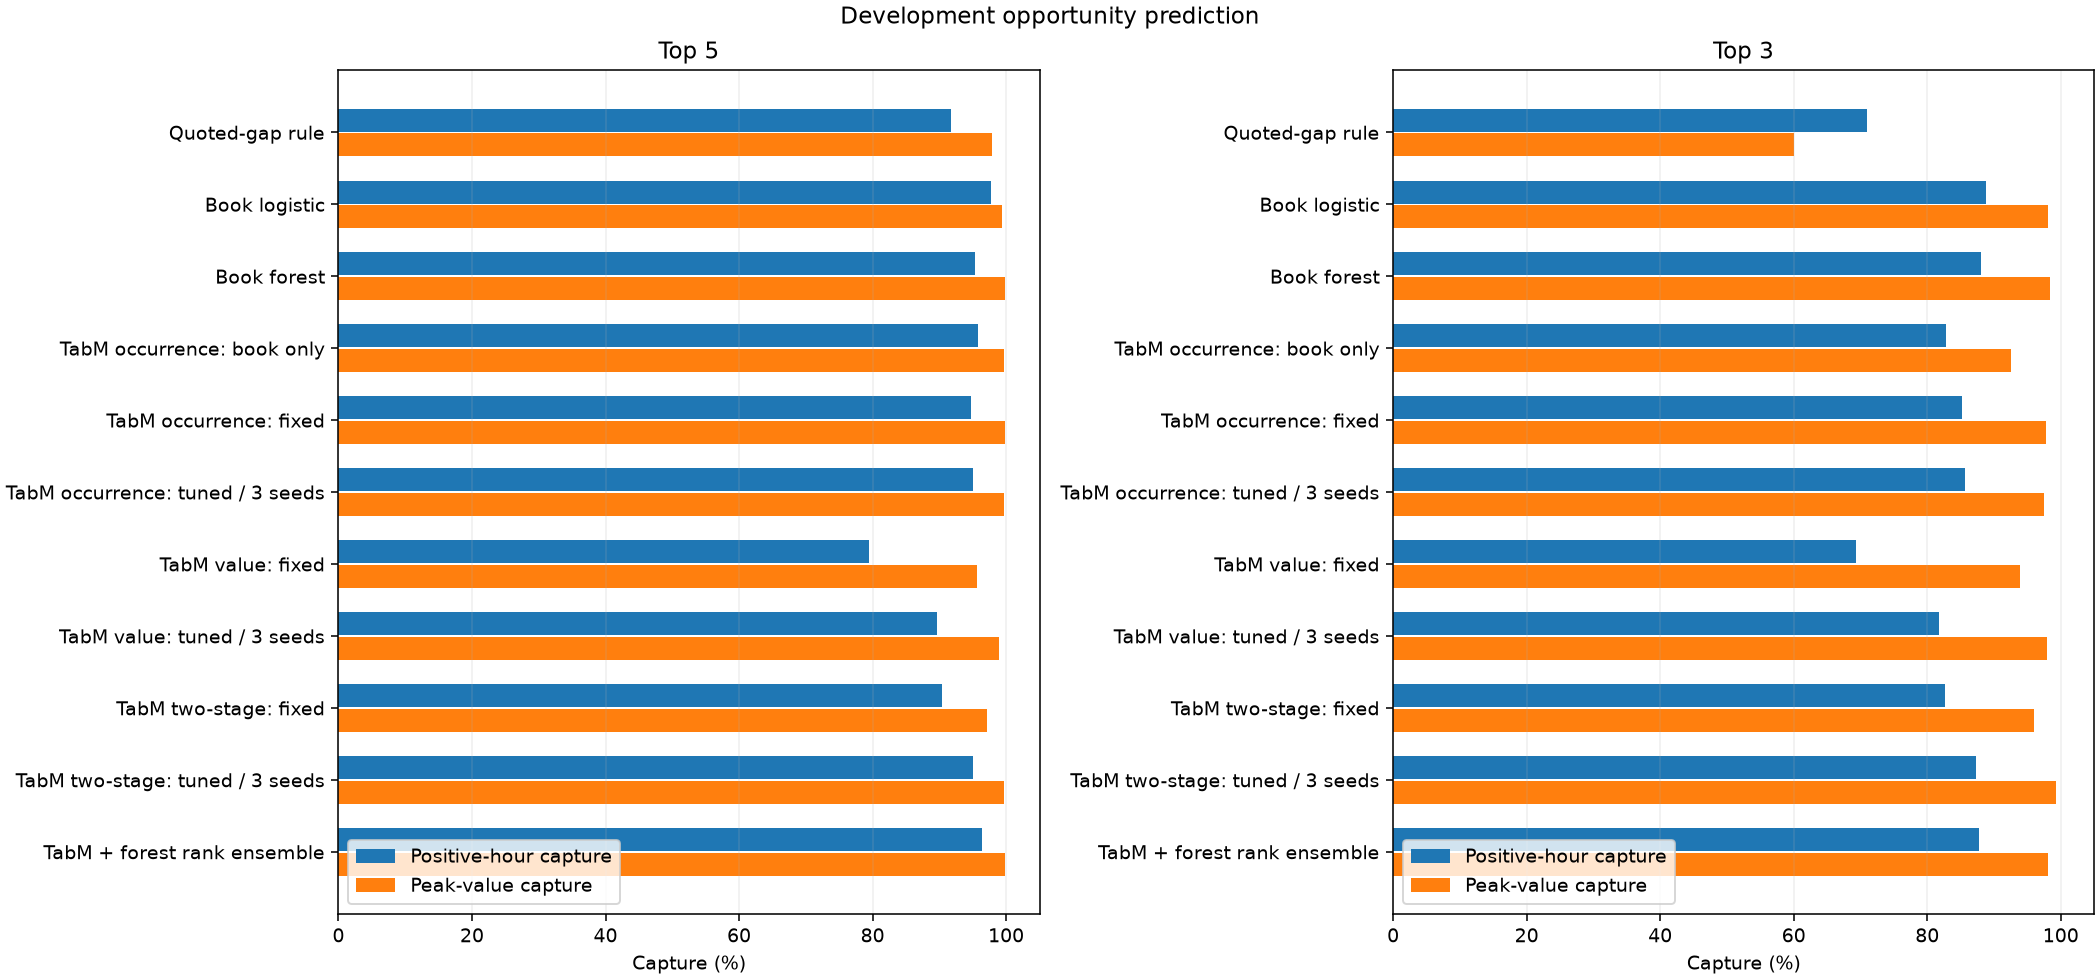

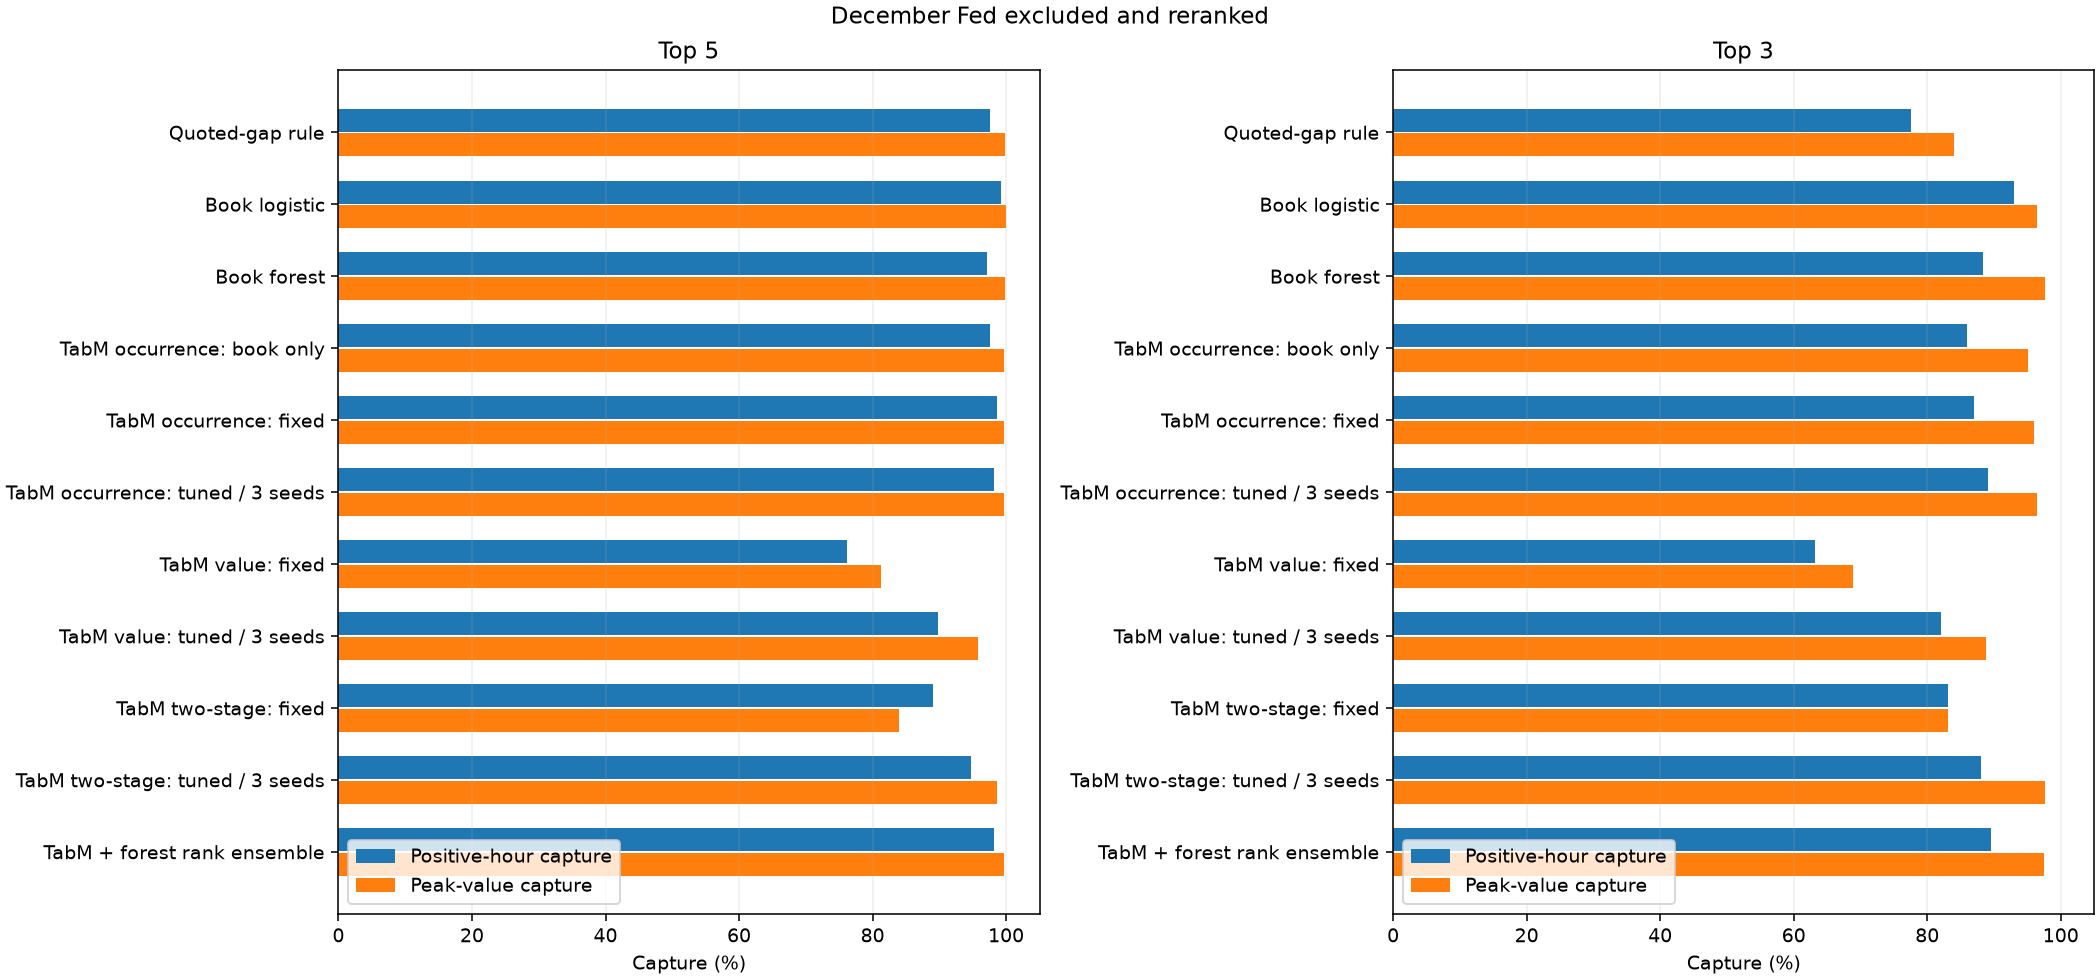

In [3]:
comparison = pd.read_csv(MODELS / 'analysis/comparison.csv')
cols = ['model','top_n','captured_positive_windows','positive_windows','recall','peak_value_recall','new_without_scan_recall','selected_unknown']
display(comparison.loc[comparison.scope.eq('all_events'), cols].round(4))
display(Image(filename=str(MODELS / 'analysis/all_events_capture.png')))
display(Image(filename=str(MODELS / 'analysis/exclude_december_fed_capture.png')))

## Seed variation and feature findings

All three tuned seeds are retained, including weaker fits. The primary tuned policy averages their predictions; averaging scores is not equivalent to averaging each seed's metric. Feature permutation shuffles a group within each scan, preserving the candidate population, and uses three repeats. Effects are diagnostic, overlap across groups and are not causal.

In [4]:
metrics = pd.read_csv(MODELS / 'metrics.csv')
seeds = metrics.loc[metrics.fold.eq('all') & metrics.scope.eq('all_events') & metrics.model.str.contains('_seed', regex=False)]
display(seeds[['model','top_n','recall','peak_value_recall']].round(4))
importance = pd.read_csv(MODELS / 'feature_importance.csv')
display(importance.groupby('group')[['recall_drop','value_recall_drop']].mean().sort_values('recall_drop',ascending=False).round(4))
display(pd.read_csv(MODELS / 'analysis/paired_occurrence_intervals.csv').round(4))
print('Family intervals are exploratory: few related event families, many comparisons, no multiplicity correction.')

,model,top_n,recall,peak_value_recall
160,tabm_classifier_seed0,5,0.9610,0.9977
161,tabm_classifier_seed0,3,0.8701,0.9861
168,tabm_classifier_seed1,5,0.9506,0.9977
169,tabm_classifier_seed1,3,0.8416,0.9457
176,tabm_classifier_seed2,5,0.9506,0.9976
177,tabm_classifier_seed2,3,0.8545,0.9768
224,tabm_regression_seed0,5,0.8701,0.9855
225,tabm_regression_seed0,3,0.7610,0.9658
232,tabm_regression_seed1,5,0.8208,0.9791
233,tabm_regression_seed1,3,0.7299,0.9668


,recall_drop,value_recall_drop
group,,
depth_size,0.2551,0.2390
history,0.0751,0.0635
quoted_gap,0.0662,0.0344
metadata,0.0026,0.0017
spread,-0.0008,0.0007
freshness_quality,-0.0072,0.0038


,model,top_n,families,recall_difference,lower,upper,draws
0,fixed_book_logistic,3,9,0.1792,0.0000,0.2170,10000
1,fixed_book_random_forest,3,9,0.1714,0.0192,0.2050,10000
2,fixed_combined_random_forest,3,9,0.1584,-0.0318,0.2016,10000
3,quoted_gap_rule,3,9,0.0000,0.0000,0.0000,10000
4,tabm_fixed_book_classifier,3,9,0.1195,-0.0851,0.1622,10000
5,tabm_fixed_classifier,3,9,0.1429,-0.1269,0.1948,10000
6,tabm_fixed_regression,3,9,-0.0156,-0.1909,0.0334,10000
7,tabm_fixed_two_stage,3,9,0.1169,-0.1965,0.2072,10000
8,tabm_forest_rank_ensemble,3,9,0.1688,-0.0345,0.2094,10000
9,tabm_tuned_classifier,3,9,0.1481,-0.0896,0.1921,10000


Family intervals are exploratory: few related event families, many comparisons, no multiplicity correction.


## Economic replay

The primary case is **100 ms arrival, uncapped capital and shares, no imposed failure probability**. Quantity and worst-price limits are fixed on observing a qualifying basket; per-leg fill-or-kill orders can leave a partial basket. Partial positions unwind one second after arrival. Reservations persist across hours and folds. Full-basket margins are accounted at completion, not at cash settlement.

Other arrival delays are 0, 50, 250 and 500 ms. Models and selections are held fixed. These are conditional historical simulations, not guaranteed live fills. CPU screening runtime is reported separately and is not silently added to the replay's assumed execution delay.

,model,top_n,known_pnl_usd,completed,partial_attempts,unknown_attempts,partial_pnl_usd,max_drawdown_usd,no_settlement_funding_usd
0,fixed_book_logistic,3,5999.41,427.0,16.0,0.0,-282.97,142.08,1411625.59
20,fixed_book_random_forest,3,5845.60,433.0,17.0,0.0,-414.48,205.96,1382599.40
40,fixed_combined_random_forest,3,5846.04,436.0,16.0,0.0,-413.98,205.96,1382653.96
60,monitor_all,3,5951.60,503.0,18.0,0.0,-414.75,205.91,1452791.40
80,quoted_gap_rule,3,4379.96,364.0,12.0,0.0,-118.16,44.48,1109836.04
100,tuned_value_ensemble,3,4894.95,413.0,12.0,0.0,-242.37,142.08,1190945.05
120,tuned_value_two_stage_random_forest,3,4635.97,410.0,14.0,0.0,-270.63,142.08,1168429.03
140,fixed_book_logistic,5,5903.33,465.0,18.0,0.0,-414.75,206.15,1419921.67
160,fixed_book_random_forest,5,5939.12,490.0,18.0,0.0,-414.75,205.91,1448636.88
180,fixed_combined_random_forest,5,5942.52,493.0,18.0,0.0,-414.75,205.91,1452040.48


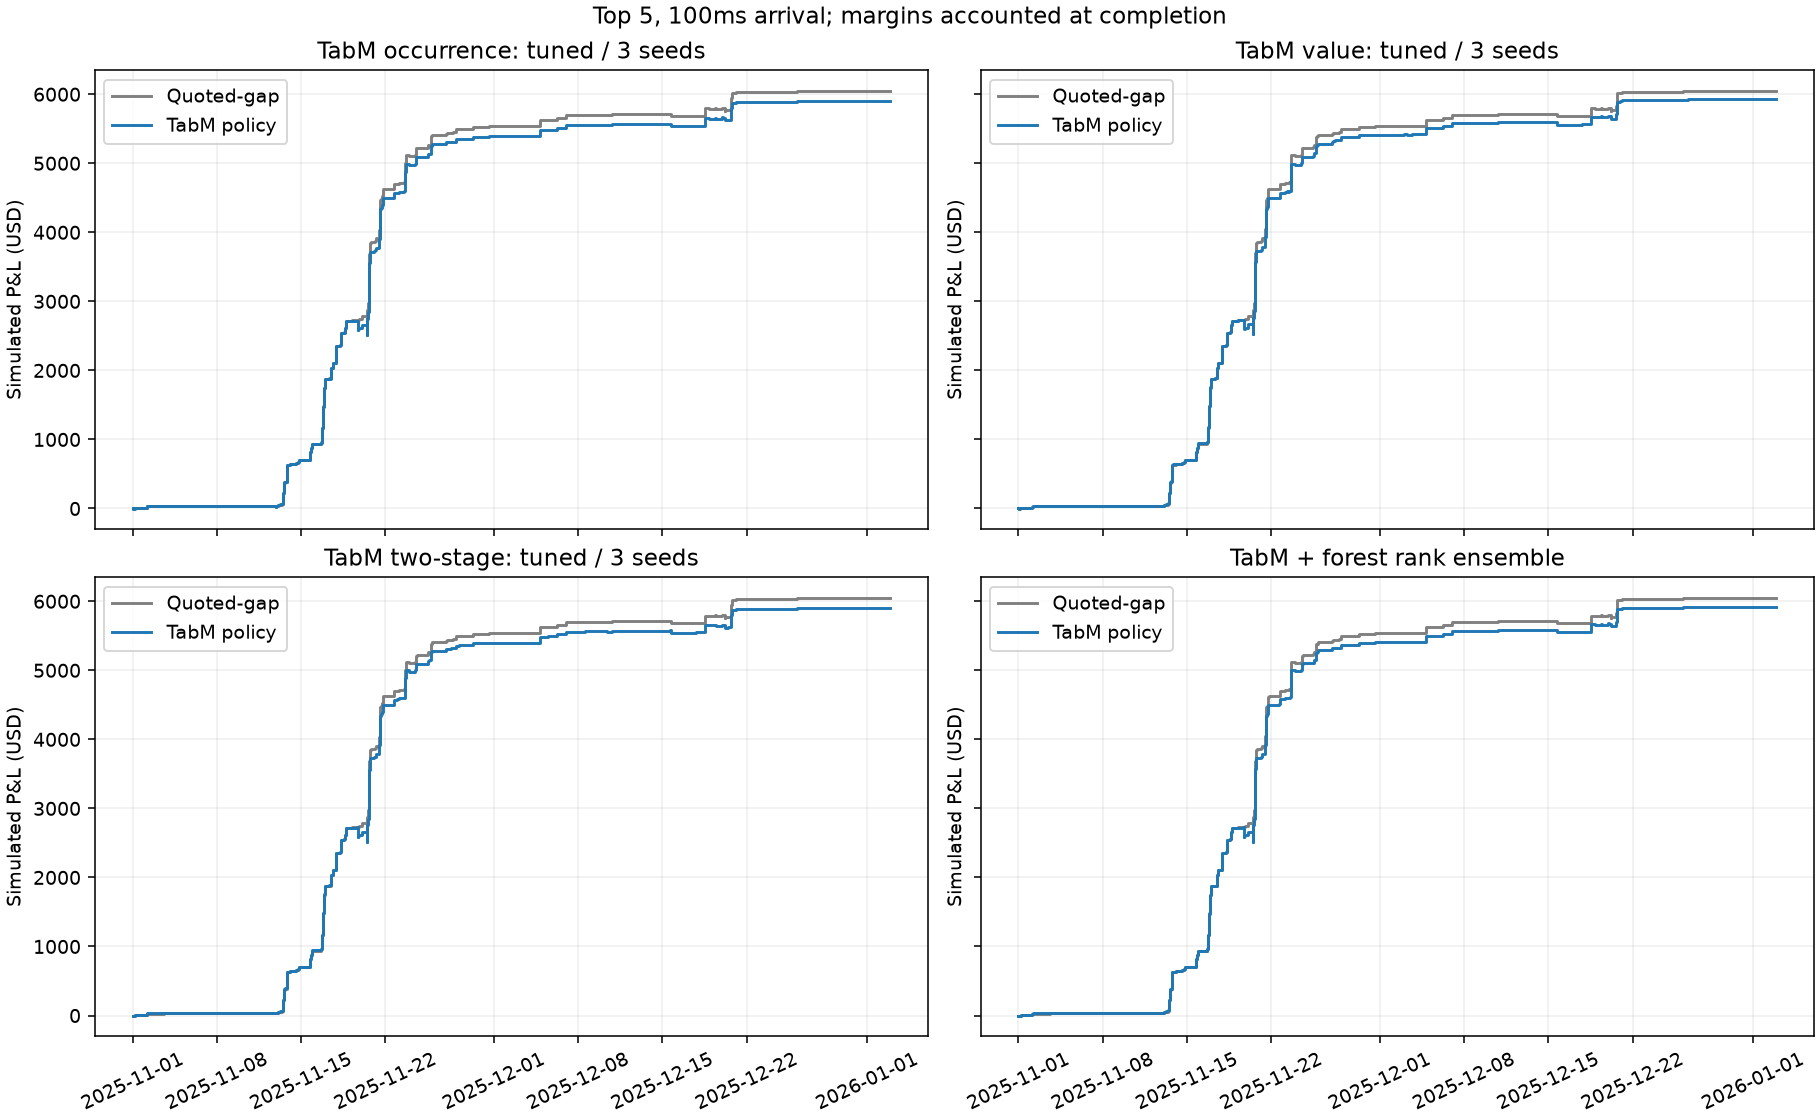

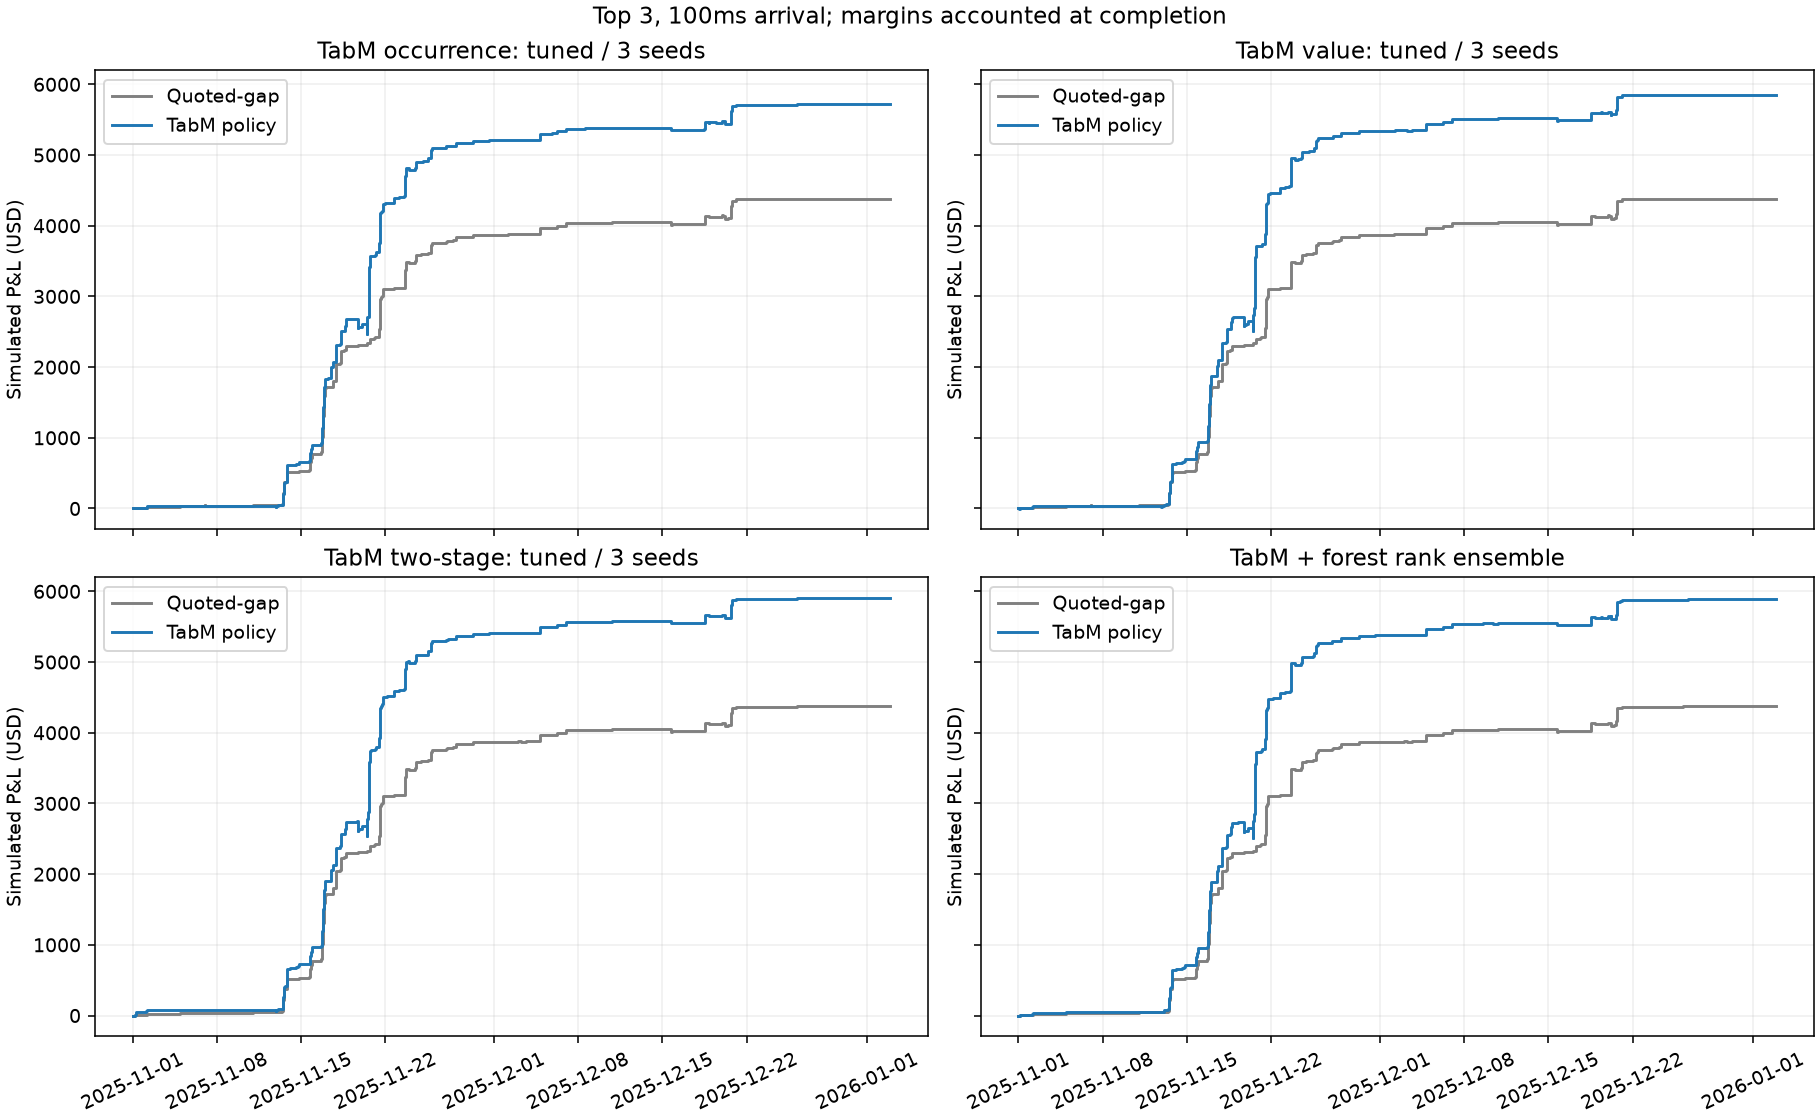

In [5]:
economic = pd.read_csv(MODELS / 'analysis/economic_comparison.csv')
primary = economic.loc[economic.fold.eq('all') & economic.arrival_delay_s.eq(.1) & economic.scope.eq('all_events')]
cols = ['model','top_n','known_pnl_usd','completed','partial_attempts','unknown_attempts','partial_pnl_usd','max_drawdown_usd','no_settlement_funding_usd']
# Summary schemas retain the original simulator field names.
display(primary[[c for c in cols if c in primary.columns]].round(2))
display(Image(filename=str(MODELS / 'analysis/top5_pnl_panels.png')))
display(Image(filename=str(MODELS / 'analysis/top3_pnl_panels.png')))

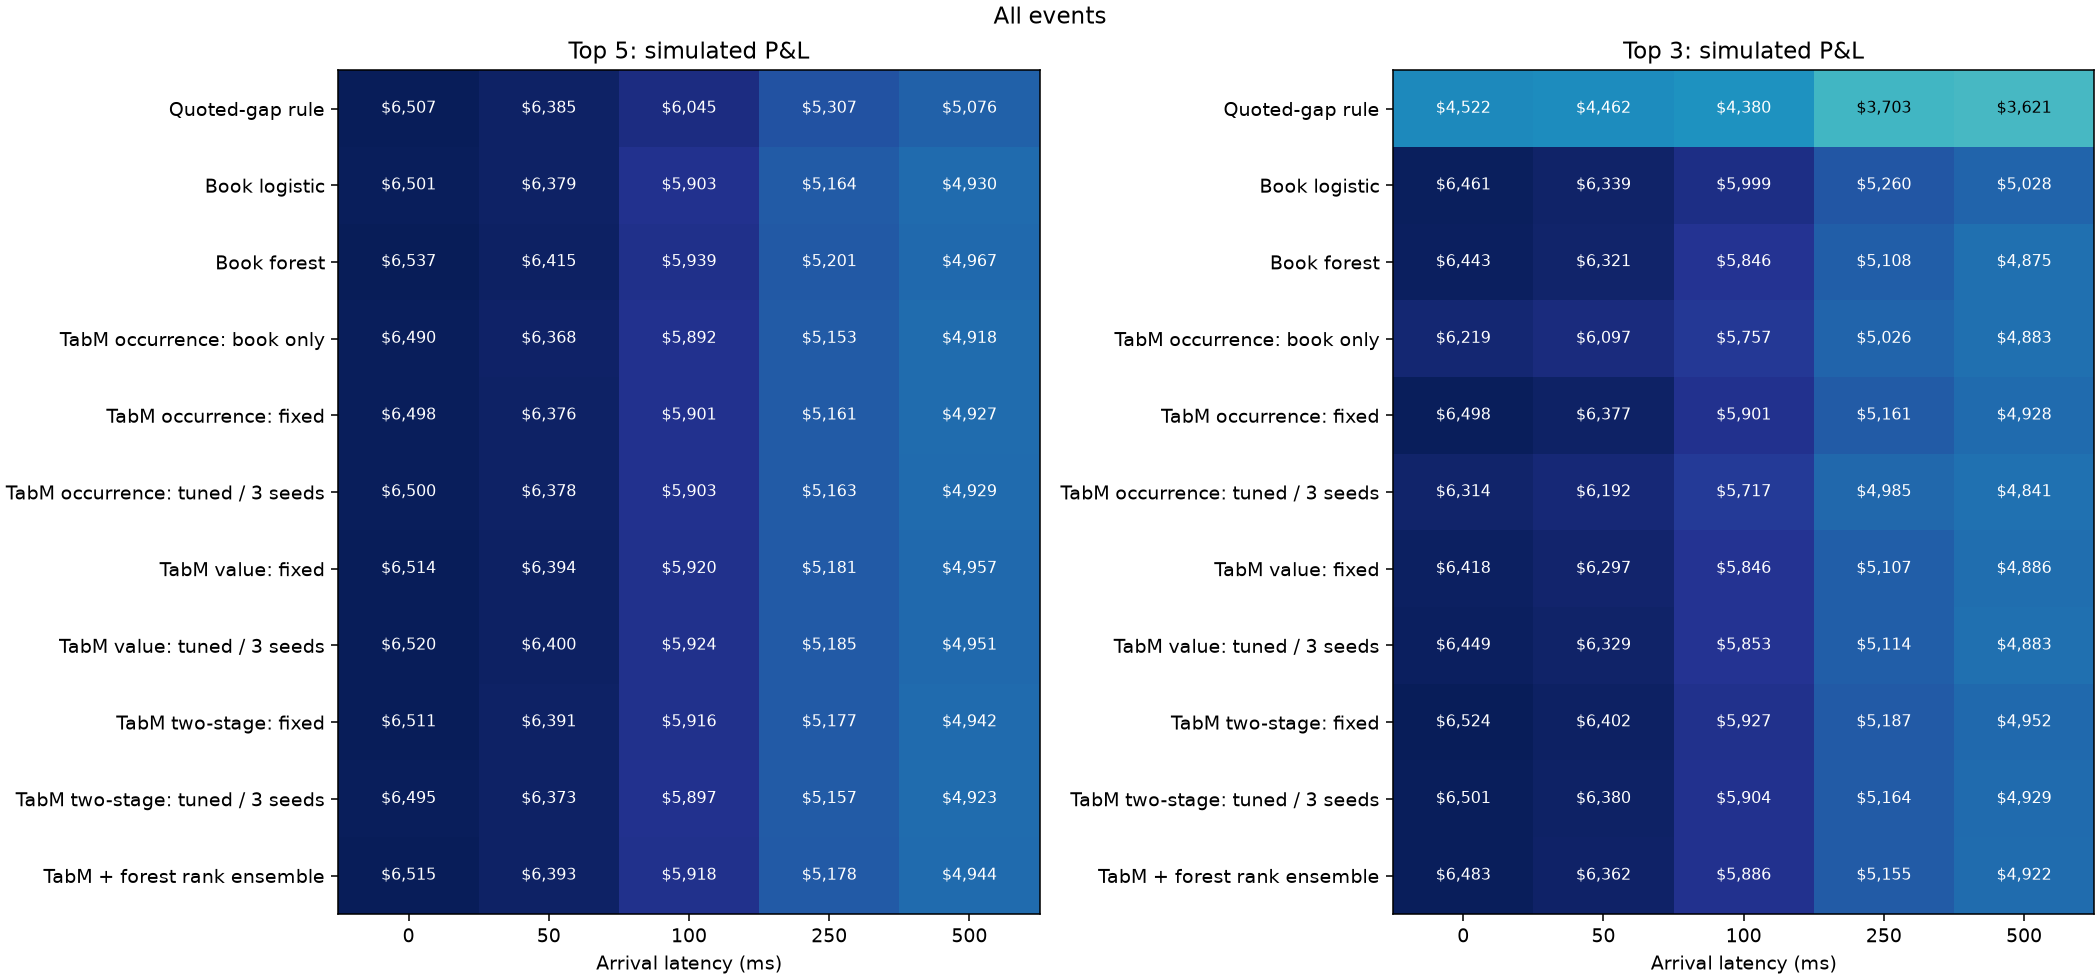

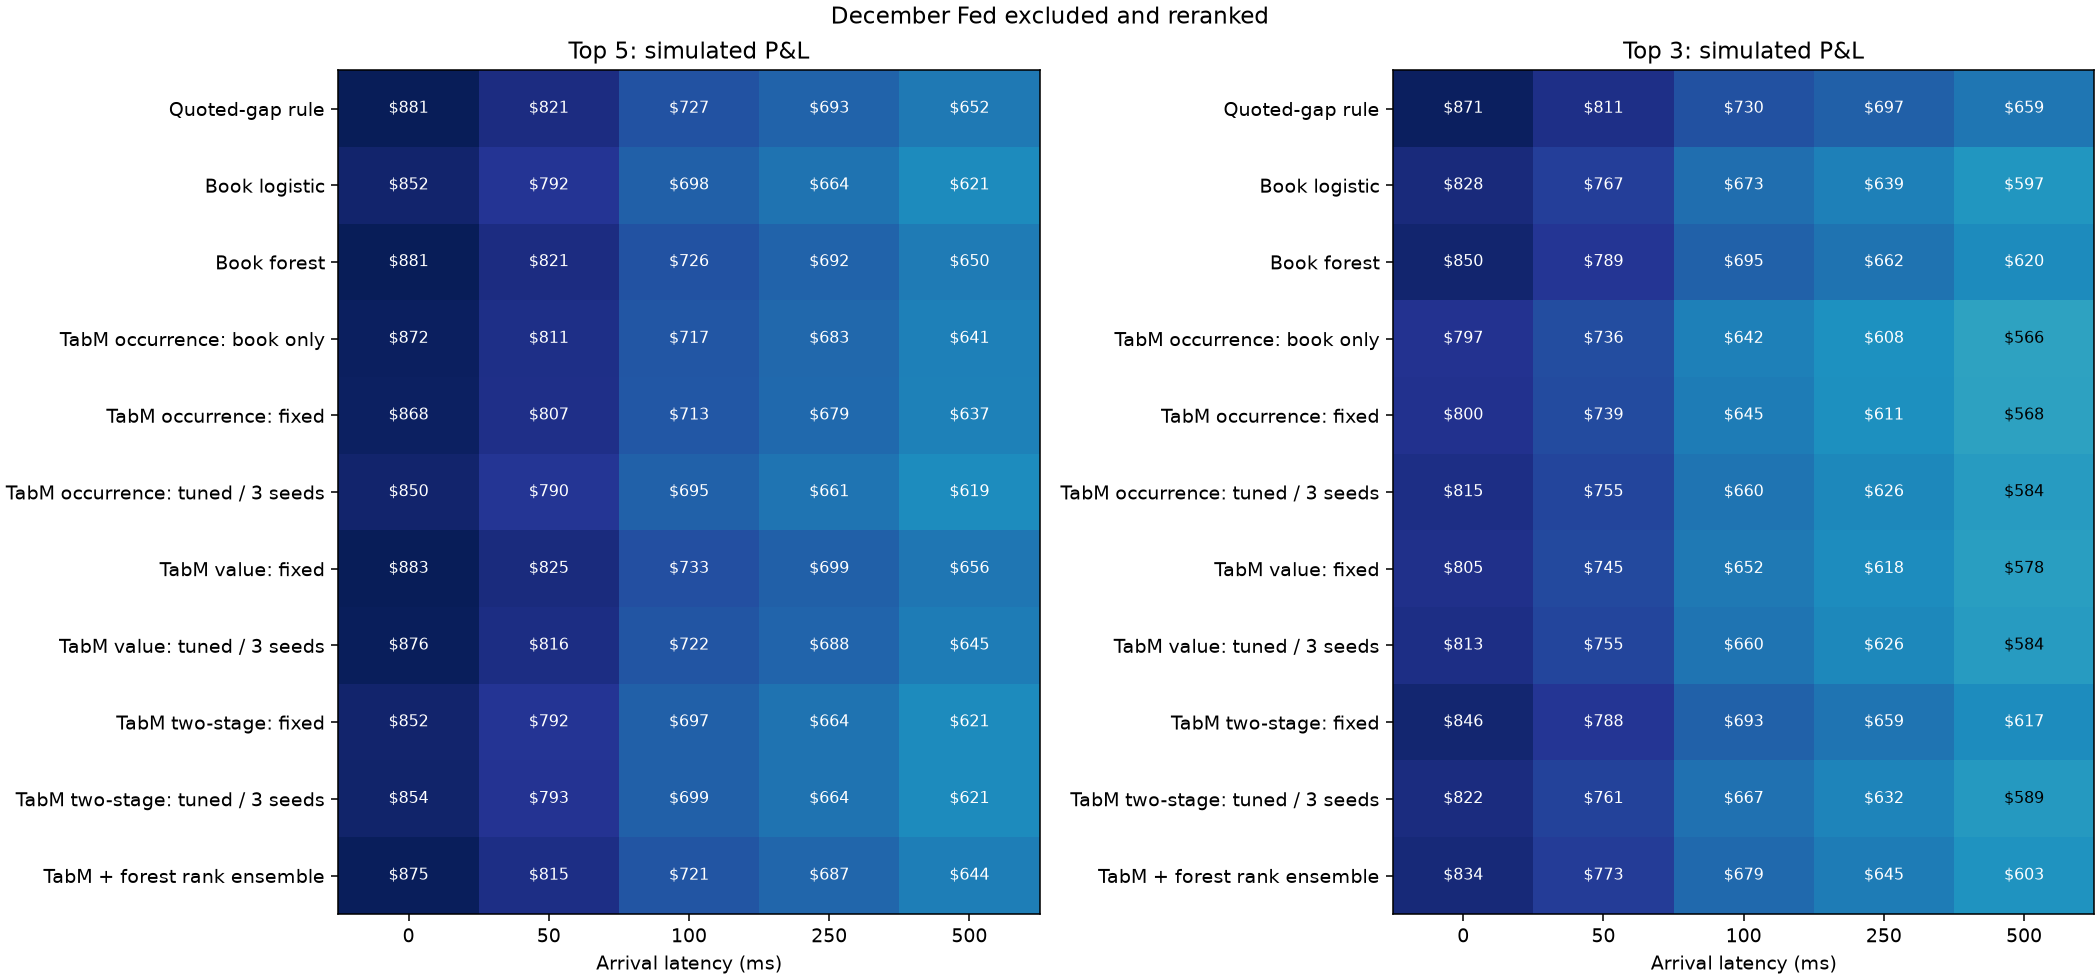

,scope,top_n,model,difference_usd,lower95,upper95
0,all_events,5,tabm_fixed_book_classifier,-153.08,-407.72,10.16
1,all_events,5,tabm_fixed_classifier,-144.72,-376.73,7.23
2,all_events,5,tabm_tuned_classifier,-142.65,-374.57,8.25
3,all_events,5,tabm_fixed_regression,-124.82,-468.19,104.81
4,all_events,5,tabm_tuned_regression,-120.92,-345.14,15.26
5,all_events,5,tabm_fixed_two_stage,-129.33,-374.74,62.09
6,all_events,5,tabm_tuned_two_stage,-147.79,-372.62,0.89
7,all_events,5,tabm_forest_rank_ensemble,-127.69,-361.11,14.03
40,all_events,3,tabm_fixed_book_classifier,1377.49,-143.53,4324.93
41,all_events,3,tabm_fixed_classifier,1521.29,-139.65,4687.38


No-settlement funding is a cash scenario, not a measured capital requirement or ROI denominator.


In [6]:
display(Image(filename=str(MODELS / 'analysis/all_events_latency.png')))
display(Image(filename=str(MODELS / 'analysis/exclude_december_fed_latency.png')))
intervals = pd.read_csv(MODELS / 'analysis/paired_pnl_intervals.csv')
display(intervals.loc[intervals.arrival_delay_s.eq(.1), ['scope','top_n','model','difference_usd','lower95','upper95']].round(2))
print('No-settlement funding is a cash scenario, not a measured capital requirement or ROI denominator.')

## Interpretation

Evaluate opportunity capture, seed stability, event concentration and replay P&L together. A recent architecture is not guaranteed to beat a simple rule or a tuned classical model. This additional development comparison follows earlier findings and should be described as exploratory. Select and freeze the final policy and execution specification before opening the untouched final test.

Full numerical findings and paper-to-implementation differences are recorded in [the TabM report](../docs/reports/tabm.md).